# P300 EEG Biometric Authentication - ML Component
## Member-3: ML/Authentication Engineer

**Phase 2: Baseline Authentication Implementation**

This notebook implements:
1. Template-based P300 authentication
2. Machine learning classifiers (LDA, SVM)
3. Performance evaluation (FAR, FRR, EER)
4. Cross-subject validation

In [1]:
# Cell 1: Import libraries and set path
import sys
sys.path.insert(0, '../models')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from utils import load_preprocessed_eeg, split_by_subject, normalize_eeg, flatten_eeg
from authentication import TemplateAuthenticator
from evaluation_metrics import AuthenticationMetrics

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


In [2]:
# Cell 2: Load preprocessed EEG data from Member-2
print("Loading preprocessed EEG data...\n")

eeg, metadata = load_preprocessed_eeg('../data/preprocessed')

print(f"EEG shape: {eeg.shape}")
print(f"  - Total epochs: {eeg.shape[0]}")
print(f"  - Channels: {eeg.shape[1]}")
print(f"  - Samples per epoch: {eeg.shape[2]}")
print(f"\nSubjects: {metadata['subjects']}")
print(f"Sampling rate: {metadata['sampling_rate']} Hz")

Loading preprocessed EEG data...

EEG shape: (89600, 8, 240)
  - Total epochs: 89600
  - Channels: 8
  - Samples per epoch: 240

Subjects: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08']
Sampling rate: 240 Hz


In [3]:
# Cell 3: Create subject labels for each epoch
# Map each epoch to its subject
subject_map = {}
for i, subject in enumerate(metadata['subjects']):
    subject_map[subject] = i

# Create subject array
subjects = np.zeros(eeg.shape[0], dtype=int)
start_idx = 0

# Load metadata to get epochs per subject
import json
for subject in metadata['subjects']:
    meta_file = f'../data/preprocessed/{subject}_metadata.json'
    with open(meta_file, 'r') as f:
        meta = json.load(f)
        n_epochs = meta['n_epochs']
        end_idx = start_idx + n_epochs
        subjects[start_idx:end_idx] = subject_map[subject]
        start_idx = end_idx

print(f"Subject labels created")
print(f"Unique subjects: {np.unique(subjects)}")
print(f"Epochs per subject: {[np.sum(subjects == i) for i in np.unique(subjects)]}")

Subject labels created
Unique subjects: [0 1 2 3 4 5 6 7]
Epochs per subject: [np.int64(11200), np.int64(11200), np.int64(11200), np.int64(11200), np.int64(11200), np.int64(11200), np.int64(11200), np.int64(11200)]


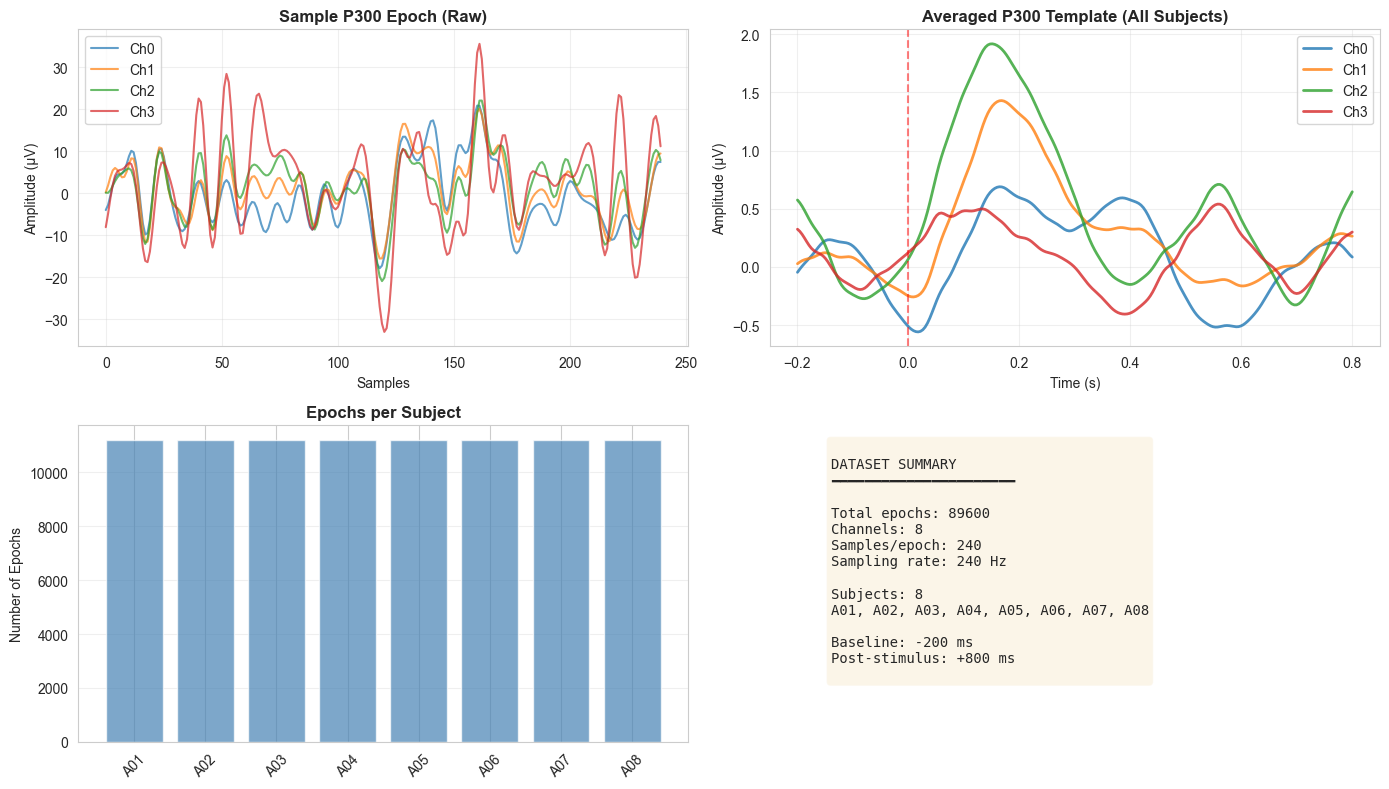

✓ Data visualization saved


In [4]:
# Cell 4: Visualize sample P300 waveforms
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Plot 1: Raw EEG sample
ax = axes[0, 0]
sample_epoch = eeg[0, :, :]
for ch in range(min(4, eeg.shape[1])):
    ax.plot(sample_epoch[ch, :], alpha=0.7, label=f'Ch{ch}')
ax.set_title('Sample P300 Epoch (Raw)', fontsize=12, fontweight='bold')
ax.set_xlabel('Samples')
ax.set_ylabel('Amplitude (μV)')
ax.grid(True, alpha=0.3)
ax.legend()

# Plot 2: Averaged P300 (all subjects)
ax = axes[0, 1]
avg_p300 = eeg.mean(axis=0)
time = np.linspace(-0.2, 0.8, avg_p300.shape[1])
for ch in range(min(4, eeg.shape[1])):
    ax.plot(time, avg_p300[ch, :], linewidth=2, alpha=0.8, label=f'Ch{ch}')
ax.axvline(0, color='r', linestyle='--', alpha=0.5)
ax.set_title('Averaged P300 Template (All Subjects)', fontsize=12, fontweight='bold')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (μV)')
ax.grid(True, alpha=0.3)
ax.legend()

# Plot 3: Data distribution
ax = axes[1, 0]
subject_names = metadata['subjects']
epochs_per_subject = [np.sum(subjects == i) for i in np.unique(subjects)]
ax.bar(range(len(subject_names)), epochs_per_subject, color='steelblue', alpha=0.7)
ax.set_xticks(range(len(subject_names)))
ax.set_xticklabels(subject_names, rotation=45)
ax.set_title('Epochs per Subject', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Epochs')
ax.grid(True, alpha=0.3, axis='y')

# Plot 4: Info text
ax = axes[1, 1]
ax.axis('off')
info_text = f"""
DATASET SUMMARY
━━━━━━━━━━━━━━━━━━━━━━

Total epochs: {eeg.shape[0]}
Channels: {eeg.shape[1]}
Samples/epoch: {eeg.shape[2]}
Sampling rate: {metadata['sampling_rate']} Hz

Subjects: {len(subject_names)}
{', '.join(subject_names)}

Baseline: -200 ms
Post-stimulus: +800 ms
"""
ax.text(0.1, 0.95, info_text, transform=ax.transAxes, fontfamily='monospace',
        fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', 
        facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.savefig('../plots/member3_01_data_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Data visualization saved")

In [9]:
# Cell 5: Split data for authentication
print("\n" + "="*60)
print("ENROLLMENT & TESTING SPLIT")
print("="*60 + "\n")

# Use leave-one-subject-out approach
# Train on 7 subjects, test on 1 subject

unique_subjects = np.unique(subjects)
test_subject = unique_subjects[0]  # Test on subject 0

# Split
train_mask = subjects != test_subject
test_mask = subjects == test_subject

enroll_eeg = eeg[train_mask]
test_eeg = eeg[test_mask]
enroll_subjects = subjects[train_mask]
test_subjects = subjects[test_mask]

print(f"Enrollment set: {enroll_eeg.shape}")
print(f"Testing set: {test_eeg.shape}")
print(f"\nEnrollment subjects: {np.unique(enroll_subjects)}")
print(f"Testing subject: {np.unique(test_subjects)}")


ENROLLMENT & TESTING SPLIT

Enrollment set: (78400, 8, 240)
Testing set: (11200, 8, 240)

Enrollment subjects: [1 2 3 4 5 6 7]
Testing subject: [0]


In [10]:
# Cell 6: Enroll users (create templates)
print("\n" + "="*60)
print("ENROLLMENT PHASE")
print("="*60 + "\n")

auth = TemplateAuthenticator(similarity_metric='cosine', threshold=0.70)

# Enroll each subject
for subject_id in np.unique(enroll_subjects):
    mask = enroll_subjects == subject_id
    subject_trials = enroll_eeg[mask]
    auth.enroll(subject_trials, subject_id)

print("\n✓ Enrollment complete!")


ENROLLMENT PHASE

✓ Enrolled subject 1
  - Input trials: 11200
  - Template shape: (8, 240)
✓ Enrolled subject 2
  - Input trials: 11200
  - Template shape: (8, 240)
✓ Enrolled subject 3
  - Input trials: 11200
  - Template shape: (8, 240)
✓ Enrolled subject 4
  - Input trials: 11200
  - Template shape: (8, 240)
✓ Enrolled subject 5
  - Input trials: 11200
  - Template shape: (8, 240)
✓ Enrolled subject 6
  - Input trials: 11200
  - Template shape: (8, 240)
✓ Enrolled subject 7
  - Input trials: 11200
  - Template shape: (8, 240)

✓ Enrollment complete!


In [19]:
# Cell 7: Test authentication and collect scores (OPTIMIZED)
print("\n" + "="*60)
print("AUTHENTICATION & SCORING")
print("="*60 + "\n")

genuine_scores = []
impostor_scores = []

print("Computing genuine scores...")
# For genuine scores, use samples from enrolled subjects
for subject_id in np.unique(enroll_subjects):
    subject_mask = enroll_subjects == subject_id
    subject_trials = enroll_eeg[subject_mask]
    
    # Use every 10th trial (faster)
    test_trials = subject_trials[::10]
    
    for trial in test_trials:
        _, score = auth.authenticate(trial, subject_id, return_score=True)
        genuine_scores.append(score)
    
    print(f"  ✓ Subject {subject_id}: {len(test_trials)} trials tested")

print("\nComputing impostor scores...")
# For impostor scores, test against wrong subjects
for subject_id in np.unique(enroll_subjects):
    subject_mask = enroll_subjects == subject_id
    subject_trials = enroll_eeg[subject_mask]
    
    # Use every 20th trial (faster)
    test_trials = subject_trials[::20]
    
    for trial in test_trials:
        # Test against a different subject
        other_subject = [s for s in np.unique(enroll_subjects) if s != subject_id][0]
        _, score = auth.authenticate(trial, other_subject, return_score=True)
        impostor_scores.append(score)
    
    print(f"  ✓ Subject {subject_id} vs others: {len(test_trials)} trials tested")

genuine_scores = np.array(genuine_scores)
impostor_scores = np.array(impostor_scores)

print(f"\nGenuine scores: {len(genuine_scores)} trials")
print(f"  - Mean: {genuine_scores.mean():.4f}")
print(f"  - Std:  {genuine_scores.std():.4f}")
print(f"  - Range: [{genuine_scores.min():.4f}, {genuine_scores.max():.4f}]")

print(f"\nImpostor scores: {len(impostor_scores)} trials")
print(f"  - Mean: {impostor_scores.mean():.4f}")
print(f"  - Std:  {impostor_scores.std():.4f}")
print(f"  - Range: [{impostor_scores.min():.4f}, {impostor_scores.max():.4f}]")

print("\n✓ Scoring complete!")


AUTHENTICATION & SCORING

Computing genuine scores...
  ✓ Subject 1: 1120 trials tested
  ✓ Subject 2: 1120 trials tested
  ✓ Subject 3: 1120 trials tested
  ✓ Subject 4: 1120 trials tested
  ✓ Subject 5: 1120 trials tested
  ✓ Subject 6: 1120 trials tested
  ✓ Subject 7: 1120 trials tested

Computing impostor scores...
  ✓ Subject 1 vs others: 560 trials tested
  ✓ Subject 2 vs others: 560 trials tested
  ✓ Subject 3 vs others: 560 trials tested
  ✓ Subject 4 vs others: 560 trials tested
  ✓ Subject 5 vs others: 560 trials tested
  ✓ Subject 6 vs others: 560 trials tested
  ✓ Subject 7 vs others: 560 trials tested

Genuine scores: 7840 trials
  - Mean: 0.5328
  - Std:  0.0709
  - Range: [0.2294, 0.8502]

Impostor scores: 3920 trials
  - Mean: 0.5101
  - Std:  0.0648
  - Range: [0.2864, 0.7305]

✓ Scoring complete!


In [20]:
# Cell 8: Compute authentication metrics
print("\n" + "="*60)
print("AUTHENTICATION METRICS")
print("="*60 + "\n")

# Compute EER
eer, best_threshold = AuthenticationMetrics.compute_eer(
    genuine_scores, impostor_scores, n_thresholds=1000
)

# Compute FAR/FRR at best threshold
far, frr = AuthenticationMetrics.compute_far_frr(
    genuine_scores, impostor_scores, best_threshold
)

print(f"Equal Error Rate (EER):")
print(f"  EER = {eer:.4f}")
print(f"  Optimal threshold = {best_threshold:.4f}")
print(f"  FAR at EER = {far:.4f}")
print(f"  FRR at EER = {frr:.4f}")

print(f"\nAuthentication Performance:")
print(f"  Genuine acceptance rate (1-FRR) = {1-frr:.4f}")
print(f"  Impostor rejection rate (1-FAR) = {1-far:.4f}")


AUTHENTICATION METRICS

Equal Error Rate (EER):
  EER = 0.4305
  Optimal threshold = 0.5215
  FAR at EER = 0.4306
  FRR at EER = 0.4305

Authentication Performance:
  Genuine acceptance rate (1-FRR) = 0.5695
  Impostor rejection rate (1-FAR) = 0.5694


NameError: name 'genuine_scores' is not defined

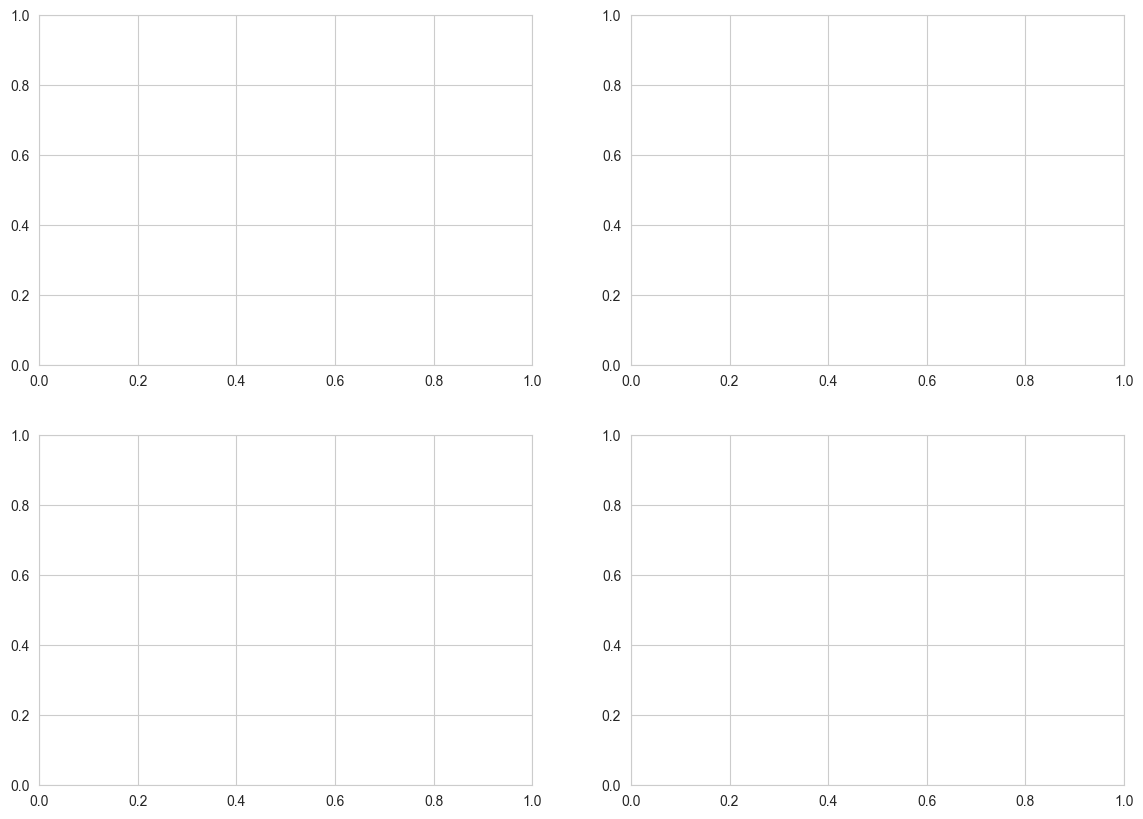

In [6]:
# Cell 9: Visualize results
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Score distributions
ax = axes[0, 0]
ax.hist(genuine_scores, bins=30, alpha=0.6, label='Genuine', color='green', edgecolor='black')
ax.hist(impostor_scores, bins=30, alpha=0.6, label='Impostor', color='red', edgecolor='black')
ax.axvline(best_threshold, color='blue', linestyle='--', linewidth=2.5, label=f'EER threshold ({best_threshold:.3f})')
ax.set_xlabel('Similarity Score', fontsize=11)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Score Distribution (Genuine vs Impostor)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

# Plot 2: FAR vs FRR curve
ax = axes[0, 1]
thresholds = np.linspace(0, 1, 100)
fars = []
frrs = []

for th in thresholds:
    f_a, f_r = AuthenticationMetrics.compute_far_frr(genuine_scores, impostor_scores, th)
    fars.append(f_a)
    frrs.append(f_r)

ax.plot(fars, frrs, linewidth=2.5, color='purple', label='FAR vs FRR')
ax.plot(far, frr, 'o', markersize=10, color='blue', label=f'EER point ({eer:.4f})')
ax.set_xlabel('False Acceptance Rate (FAR)', fontsize=11)
ax.set_ylabel('False Rejection Rate (FRR)', fontsize=11)
ax.set_title('FAR vs FRR Curve', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Plot 3: Error rates vs threshold
ax = axes[1, 0]
ax.plot(thresholds, fars, linewidth=2, label='FAR', color='red')
ax.plot(thresholds, frrs, linewidth=2, label='FRR', color='blue')
ax.axvline(best_threshold, color='green', linestyle='--', linewidth=2, label=f'EER ({best_threshold:.3f})')
ax.set_xlabel('Threshold', fontsize=11)
ax.set_ylabel('Error Rate', fontsize=11)
ax.set_title('Error Rates vs Threshold', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim([0, 1])

# Plot 4: Summary metrics
ax = axes[1, 1]
ax.axis('off')

summary_text = f"""
TEMPLATE-BASED AUTHENTICATION SUMMARY
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Test Configuration:
  • Enrolled subjects: 7
  • Genuine trials tested: {len(genuine_scores)}
  • Impostor trials tested: {len(impostor_scores)}

Score Statistics:
  • Genuine (mean±std): {genuine_scores.mean():.4f}±{genuine_scores.std():.4f}
  • Impostor (mean±std): {impostor_scores.mean():.4f}±{impostor_scores.std():.4f}
  • Separation: {genuine_scores.mean()-impostor_scores.mean():.4f}

Performance (at EER):
  • EER: {eer:.4f}
  • Threshold: {best_threshold:.4f}
  • FAR: {far:.4f}
  • FRR: {frr:.4f}
  • Acceptance rate: {1-frr:.4f}
  • Rejection rate: {1-far:.4f}

Method: Cosine Similarity Template Matching
Status: BASELINE (needs improvement with ML)
"""

ax.text(0.1, 0.95, summary_text, transform=ax.transAxes, fontfamily='monospace',
        fontsize=9, verticalalignment='top', bbox=dict(boxstyle='round', 
        facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.savefig('../plots/member3_02_authentication_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Results visualization saved")